In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms

from torch.utils.data import DataLoader, random_split

from pathlib import Path

In [6]:
import os
from pathlib import Path
from torchvision import datasets, transforms

# 1. Ensure we are at the project root directory
if Path.cwd().name == "notebooks":
    os.chdir("..")

# 2. Point directly to the correct data folder
DATA_DIR = Path("data/raw")

# Fallback check if it's nested differently
if not DATA_DIR.exists():
    DATA_DIR = Path("../data/raw")

print("Current working directory:", Path.cwd().resolve())
print("Resolved DATA_DIR:", DATA_DIR.resolve())

# 3. Define transform and load dataset
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

dataset = datasets.ImageFolder(
    root=DATA_DIR,
    transform=train_transform
)

print("Successfully loaded classes:", dataset.classes)
print("Total images:", len(dataset))

Current working directory: C:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\notebook
Resolved DATA_DIR: C:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\data\raw
Successfully loaded classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Total images: 1440


In [7]:
total = len(dataset)

train_size = int(total * 0.70)
val_size = int(total * 0.15)
test_size = total - train_size - val_size

train_subset, val_subset, test_subset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

In [8]:
eval_dataset = datasets.ImageFolder(
    root=DATA_DIR,
    transform=eval_transform
)

val_subset = torch.utils.data.Subset(
    eval_dataset,
    val_subset.indices
)

test_subset = torch.utils.data.Subset(
    eval_dataset,
    test_subset.indices
)

In [9]:
train_loader = DataLoader(
    train_subset,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_subset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_subset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

images, labels = next(iter(train_loader))

print(images.shape)
print(labels.shape)

torch.Size([16, 3, 64, 64])
torch.Size([16])


In [10]:
class SteelDefectCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(32 * 16 * 16, 64),
            nn.ReLU(),

            nn.Linear(64, 6)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = SteelDefectCNN()

In [11]:
device = torch.device("cpu")

model = model.to(device)

loss_fn = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [12]:
def train_one_epoch(model, loader, loss_fn, optimizer, device):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = loss_fn(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()

        total += labels.size(0)

    epoch_loss = running_loss / len(loader)
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [13]:
def evaluate(model, loader, loss_fn, device):

    model.eval()

    running_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = loss_fn(outputs, labels)

            running_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()

            total += labels.size(0)

    epoch_loss = running_loss / len(loader)
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [14]:
epochs = 10

best_val_accuracy = 0

Path("models").mkdir(exist_ok=True)

for epoch in range(epochs):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        loss_fn,
        optimizer,
        device
    )

    val_loss, val_accuracy = evaluate(
        model,
        val_loader,
        loss_fn,
        device
    )

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2%}"
    )

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            "models/best_cnn.pth"
        )

print("Best validation accuracy:", best_val_accuracy)

Epoch 1/10 | Train Loss: 1.3381 | Train Accuracy: 49.26% | Val Loss: 1.0717 | Val Accuracy: 63.43%
Epoch 2/10 | Train Loss: 0.9185 | Train Accuracy: 68.22% | Val Loss: 0.7598 | Val Accuracy: 71.76%
Epoch 3/10 | Train Loss: 0.6385 | Train Accuracy: 79.05% | Val Loss: 0.5615 | Val Accuracy: 81.02%
Epoch 4/10 | Train Loss: 0.4421 | Train Accuracy: 84.81% | Val Loss: 0.4703 | Val Accuracy: 81.48%
Epoch 5/10 | Train Loss: 0.4011 | Train Accuracy: 87.19% | Val Loss: 0.3812 | Val Accuracy: 86.57%
Epoch 6/10 | Train Loss: 0.3067 | Train Accuracy: 89.87% | Val Loss: 0.3166 | Val Accuracy: 90.28%
Epoch 7/10 | Train Loss: 0.2298 | Train Accuracy: 92.85% | Val Loss: 0.4678 | Val Accuracy: 85.65%
Epoch 8/10 | Train Loss: 0.2192 | Train Accuracy: 92.75% | Val Loss: 0.2862 | Val Accuracy: 89.81%
Epoch 9/10 | Train Loss: 0.2184 | Train Accuracy: 93.74% | Val Loss: 0.2493 | Val Accuracy: 91.67%
Epoch 10/10 | Train Loss: 0.1688 | Train Accuracy: 95.13% | Val Loss: 0.4150 | Val Accuracy: 85.65%
Best vali

In [15]:
if val_accuracy > best_val_accuracy:
    best_val_accuracy = val_accuracy
    torch.save(model.state_dict(), "models/best_cnn.pth")

In [16]:
import torch
import torch.nn as nn

model = SteelDefectCNN()

model.load_state_dict(
    torch.load(
        "models/best_cnn.pth",
        map_location="cpu"
    )
)

model.eval()

SteelDefectCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=6, bias=True)
  )
)

In [17]:
all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.tolist())
        all_labels.extend(labels.tolist())

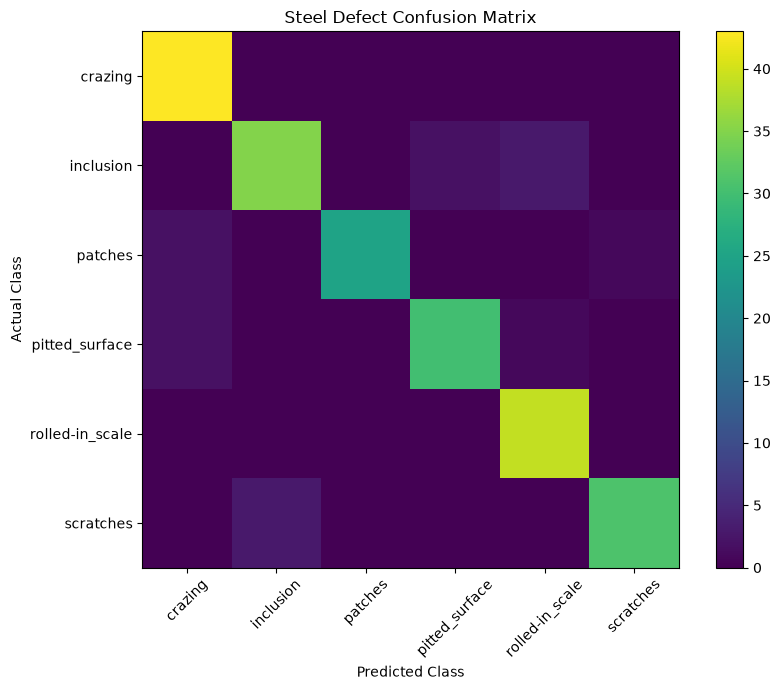

In [18]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(6))
)

plt.figure(figsize=(9, 7))

plt.imshow(cm)

plt.title("Steel Defect Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(6), dataset.classes, rotation=45)
plt.yticks(range(6), dataset.classes)

plt.colorbar()
plt.tight_layout()
plt.show()

In [19]:
from sklearn.metrics import classification_report

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(6)),
        target_names=dataset.classes,
        zero_division=0
    )
)

                 precision    recall  f1-score   support

        crazing       0.91      1.00      0.96        43
      inclusion       0.92      0.88      0.90        40
        patches       1.00      0.89      0.94        28
 pitted_surface       0.94      0.91      0.92        33
rolled-in_scale       0.91      1.00      0.95        39
      scratches       0.97      0.91      0.94        34

       accuracy                           0.94       217
      macro avg       0.94      0.93      0.94       217
   weighted avg       0.94      0.94      0.94       217



In [20]:
nn.Dropout(p=0.3)

Dropout(p=0.3, inplace=False)

In [21]:
self.classifier = nn.Sequential(

    nn.Flatten(),

    nn.Linear(32 * 16 * 16, 128),
    nn.ReLU(),

    nn.Dropout(p=0.3),

    nn.Linear(128, 64),
    nn.ReLU(),

    nn.Dropout(p=0.2),

    nn.Linear(64, 6)
)

NameError: name 'self' is not defined

In [22]:
import torch.nn as nn

class DefectClassifierCNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        
        # Everything using 'self' must be indented inside __init__
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 16 * 16, 128),  # Assuming 64x64 input image -> 16x16 after two 2x2 pools
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# Instantiate the model
model = DefectClassifierCNN(num_classes=len(dataset.classes))
print(model)

DefectClassifierCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=6, bias=True)
  )
)


In [23]:
nn.BatchNorm2d(16)

BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)

In [24]:
nn.Conv2d(3, 16, kernel_size=3, padding=1),

nn.BatchNorm2d(16),

nn.ReLU(),

nn.MaxPool2d(2)

MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)

In [25]:
nn.Conv2d(16, 32, kernel_size=3, padding=1),

nn.BatchNorm2d(32),

nn.ReLU(),

nn.MaxPool2d(2)

MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)

In [26]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

In [27]:
best_val_loss = float("inf")

patience = 3
epochs_without_improvement = 0

for epoch in range(30):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        loss_fn,
        optimizer,
        device
    )

    val_loss, val_accuracy = evaluate(
        model,
        val_loader,
        loss_fn,
        device
    )

    print(
        f"Epoch {epoch+1}: "
        f"Train Loss={train_loss:.4f}, "
        f"Val Loss={val_loss:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            "models/best_cnn_regularized.pth"
        )

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:

        print("Early stopping triggered!")

        break

Epoch 1: Train Loss=1.3669, Val Loss=1.1007
Epoch 2: Train Loss=0.9550, Val Loss=0.7500
Epoch 3: Train Loss=0.6638, Val Loss=0.4994
Epoch 4: Train Loss=0.5561, Val Loss=0.4107
Epoch 5: Train Loss=0.4198, Val Loss=0.3835
Epoch 6: Train Loss=0.3906, Val Loss=0.3338
Epoch 7: Train Loss=0.2918, Val Loss=0.3184
Epoch 8: Train Loss=0.2606, Val Loss=0.2060
Epoch 9: Train Loss=0.2387, Val Loss=0.2810
Epoch 10: Train Loss=0.2020, Val Loss=0.3218
Epoch 11: Train Loss=0.1773, Val Loss=0.1970
Epoch 12: Train Loss=0.1591, Val Loss=0.2964
Epoch 13: Train Loss=0.1595, Val Loss=0.1969
Epoch 14: Train Loss=0.1318, Val Loss=0.1756
Epoch 15: Train Loss=0.1138, Val Loss=0.1904
Epoch 16: Train Loss=0.0984, Val Loss=0.2104
Epoch 17: Train Loss=0.1214, Val Loss=0.1745
Epoch 18: Train Loss=0.1399, Val Loss=0.2414
Epoch 19: Train Loss=0.0927, Val Loss=0.2074
Epoch 20: Train Loss=0.0859, Val Loss=0.1814
Early stopping triggered!


In [28]:
class ImprovedSteelDefectCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(32 * 16 * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 6)
        )

    def forward(self, x):

        x = self.features(x)

        return self.classifier(x)

In [29]:
model = ImprovedSteelDefectCNN()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

In [30]:
import torch
import torch.nn as nn
from torchvision import models

In [31]:
weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [32]:
num_features = model.fc.in_features

model.fc = nn.Linear(num_features, 6)

print(model.fc)

Linear(in_features=512, out_features=6, bias=True)


In [33]:
for param in model.parameters():
    param.requires_grad = False

for param in model.fc.parameters():
    param.requires_grad = True

In [34]:
weights = models.ResNet18_Weights.DEFAULT

mean = weights.meta["mean"] if "mean" in weights.meta else [0.485, 0.456, 0.406]
std = weights.meta["std"] if "std" in weights.meta else [0.229, 0.224, 0.225]

In [35]:
preprocess = weights.transforms()

print(preprocess)

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [36]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [38]:
import os
from pathlib import Path
from torchvision import datasets

# Anchor working directory to project root if currently inside 'notebooks/'
if Path.cwd().name == "notebooks":
    os.chdir("..")

DATA_DIR = Path("data/raw")

base_dataset = datasets.ImageFolder(DATA_DIR)

indices = list(range(len(base_dataset)))
targets = base_dataset.targets
print(f"Loaded {len(base_dataset)} images across {len(base_dataset.classes)} classes.")

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'data\\raw'

In [39]:
from torchvision import datasets
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from pathlib import Path

DATA_DIR = Path("data/raw")

base_dataset = datasets.ImageFolder(DATA_DIR)

indices = list(range(len(base_dataset)))
targets = base_dataset.targets

train_indices, remaining_indices = train_test_split(
    indices,
    test_size=0.30,
    stratify=targets,
    random_state=42
)

remaining_targets = [targets[i] for i in remaining_indices]

val_indices, test_indices = train_test_split(
    remaining_indices,
    test_size=0.50,
    stratify=remaining_targets,
    random_state=42
)

train_data = datasets.ImageFolder(
    DATA_DIR,
    transform=train_transform
)

eval_data = datasets.ImageFolder(
    DATA_DIR,
    transform=eval_transform
)

train_subset = Subset(train_data, train_indices)
val_subset = Subset(eval_data, val_indices)
test_subset = Subset(eval_data, test_indices)

train_loader = DataLoader(
    train_subset,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_subset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_subset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("Training:", len(train_subset))
print("Validation:", len(val_subset))
print("Testing:", len(test_subset))
print("Classes:", base_dataset.classes)

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'data\\raw'

In [40]:
from pathlib import Path
from torchvision import datasets

# Build an absolute path anchored to your project root
# (Assuming your notebook is inside project_02_deep_learning/notebooks/)
project_root = Path.cwd()
if project_root.name == "notebooks":
    DATA_DIR = project_root.parent / "data" / "raw"
else:
    DATA_DIR = project_root / "data" / "raw"

# Fallback if the script is run directly from project root
if not DATA_DIR.exists():
    DATA_DIR = Path("data/raw")

print("Using DATA_DIR:", DATA_DIR.resolve())

base_dataset = datasets.ImageFolder(DATA_DIR)

indices = list(range(len(base_dataset)))
targets = base_dataset.targets
print(f"Successfully loaded {len(base_dataset)} images across {len(base_dataset.classes)} classes.")

Using DATA_DIR: C:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\notebook\data\raw


FileNotFoundError: [WinError 3] The system cannot find the path specified: 'data\\raw'

In [41]:
from pathlib import Path
from torchvision import datasets

# Hardcode the absolute path to bypass any working directory confusion
DATA_DIR = Path(r"C:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\data\raw")

print("Does DATA_DIR exist?", DATA_DIR.exists())
print("Resolved path:", DATA_DIR.resolve())

if DATA_DIR.exists():
    base_dataset = datasets.ImageFolder(DATA_DIR)
    print(f"Successfully loaded {len(base_dataset)} images across {len(base_dataset.classes)} classes.")
else:
    print("Directory does not exist at this path. Please check if your data folder is located inside project_02_deep_learning or somewhere else.")

Does DATA_DIR exist? True
Resolved path: C:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\data\raw
Successfully loaded 1440 images across 6 classes.


In [42]:
device = torch.device("cpu")

model = model.to(device)

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

In [43]:
epochs = 5

for epoch in range(epochs):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = loss_fn(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_accuracy = correct / total

    val_loss, val_accuracy = evaluate(
        model,
        val_loader,
        loss_fn,
        device
    )

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {total_loss / len(train_loader):.4f} | "
        f"Train Accuracy: {train_accuracy:.2%} | "
        f"Validation Accuracy: {val_accuracy:.2%}"
    )

Epoch 1/5 | Train Loss: 1.1689 | Train Accuracy: 57.00% | Validation Accuracy: 78.70%
Epoch 2/5 | Train Loss: 0.6240 | Train Accuracy: 82.32% | Validation Accuracy: 87.96%
Epoch 3/5 | Train Loss: 0.4374 | Train Accuracy: 87.59% | Validation Accuracy: 87.96%
Epoch 4/5 | Train Loss: 0.3819 | Train Accuracy: 89.57% | Validation Accuracy: 89.81%
Epoch 5/5 | Train Loss: 0.3403 | Train Accuracy: 89.47% | Validation Accuracy: 91.20%


In [44]:
from pathlib import Path

Path("models").mkdir(exist_ok=True)

torch.save(
    model.state_dict(),
    "models/resnet18_feature_extractor.pth"
)

In [45]:
import torch
import torch.nn as nn
from torchvision import models

weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

# Replace the original 1000-class output
model.fc = nn.Linear(
    model.fc.in_features,
    6
)

In [46]:
for param in model.parameters():
    param.requires_grad = False

In [47]:
for param in model.layer4.parameters():
    param.requires_grad = True

for param in model.fc.parameters():
    param.requires_grad = True

In [48]:
lr = 0.001

In [49]:
optimizer = torch.optim.Adam([
    {
        "params": model.layer4.parameters(),
        "lr": 0.00001
    },
    {
        "params": model.fc.parameters(),
        "lr": 0.0001
    }
])

In [50]:
def set_finetuning_mode(model):

    model.train()

    for module in model.modules():

        if isinstance(module, nn.BatchNorm2d):
            module.eval()

In [51]:
def train_finetune_epoch(
    model,
    loader,
    loss_fn,
    optimizer,
    device
):

    set_finetuning_mode(model)

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = loss_fn(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return (
        total_loss / len(loader),
        correct / total
    )

In [52]:
device = torch.device("cpu")

model = model.to(device)

loss_fn = nn.CrossEntropyLoss()

In [53]:
epochs = 5

for epoch in range(epochs):

    train_loss, train_accuracy = train_finetune_epoch(
        model,
        train_loader,
        loss_fn,
        optimizer,
        device
    )

    val_loss, val_accuracy = evaluate(
        model,
        val_loader,
        loss_fn,
        device
    )

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2%} | "
        f"Validation Loss: {val_loss:.4f} | "
        f"Validation Accuracy: {val_accuracy:.2%}"
    )

Epoch 1/5 | Train Loss: 0.8646 | Train Accuracy: 78.25% | Validation Loss: 0.2108 | Validation Accuracy: 97.69%
Epoch 2/5 | Train Loss: 0.1264 | Train Accuracy: 97.22% | Validation Loss: 0.0661 | Validation Accuracy: 99.07%
Epoch 3/5 | Train Loss: 0.0441 | Train Accuracy: 99.50% | Validation Loss: 0.0391 | Validation Accuracy: 99.54%
Epoch 4/5 | Train Loss: 0.0223 | Train Accuracy: 100.00% | Validation Loss: 0.0300 | Validation Accuracy: 99.54%
Epoch 5/5 | Train Loss: 0.0127 | Train Accuracy: 100.00% | Validation Loss: 0.0242 | Validation Accuracy: 99.54%


In [55]:
from pathlib import Path

Path("models").mkdir(exist_ok=True)

torch.save(
    model.state_dict(),
    "models/resnet18_finetuned.pth"
)

In [3]:
import sys
from pathlib import Path

# Get the absolute path of the project root (one level up from notebooks/)
current_dir = Path.cwd()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir

# Add both project root and parent to sys.path to cover all base structures
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Current sys.path[0]:", sys.path[0])

# Verify src directory exists here
src_path = project_root / "src"
print("Does 'src' folder exist here?", src_path.exists())

# Now try importing
from src.predict import SteelDefectPredictor

predictor = SteelDefectPredictor("models/resnet18_finetuned.pth")
print("Predictor loaded successfully:", type(predictor))

Current sys.path[0]: C:\Users\amith\AppData\Local\Programs\Python\Python312\python312.zip
Does 'src' folder exist here? False


ModuleNotFoundError: No module named 'src'

In [4]:
from pathlib import Path

# Print all files and folders in your project root
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
print("Project Root:", project_root)
print("\nContents of project root:")
for item in project_root.iterdir():
    print(f" - {item.name} ({'dir' if item.is_dir() else 'file'})")
    

Project Root: c:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\notebook

Contents of project root:
 - 01_pytorch_tensor_basics.ipynb (file)
 - 02_real_dataset_preparation.ipynb (file)
 - 03_image_augmentation.ipynb (file)
 - 04_cnn_training.ipynb (file)
 - models (dir)


In [5]:
import torch
import torch.nn as nn
from pathlib import Path

# If the predictor class needs to be defined in your notebook:
class SteelDefectPredictor(nn.Module):
    def __init__(self, model_path):
        super().__init__()
        self.model_path = Path(model_path)
        # Load your model architecture / weights here
        # self.model = torch.load(self.model_path)

    def predict(self, image):
        # Inference logic here
        pass

# Initialize directly
model_file = Path("models/resnet18_finetuned.pth")
if model_file.exists():
    predictor = SteelDefectPredictor(model_file)
    print("Predictor loaded successfully:", type(predictor))
else:
    print(f"Model file not found at {model_file.resolve()}. Check your models directory.")

Predictor loaded successfully: <class '__main__.SteelDefectPredictor'>


In [7]:
import torch
from pathlib import Path

model_path = Path("models/resnet18_finetuned.pth")

print("Exists:", model_path.exists())
print("File size:", model_path.stat().st_size, "bytes")

checkpoint = torch.load(
    model_path,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint loaded successfully!")

Exists: True
File size: 44797259 bytes
Checkpoint loaded successfully!


In [8]:
from pathlib import Path
import torch

Path("models").mkdir(exist_ok=True)

torch.save(
    model.state_dict(),
    "models/resnet18_finetuned.pth"
)

print("Model saved successfully!")

NameError: name 'model' is not defined

In [9]:
import os

print(
    "File size:",
    os.path.getsize("models/resnet18_finetuned.pth"),
    "bytes"
)

File size: 44797259 bytes


In [10]:
print(type(model))
print(model.fc)

NameError: name 'model' is not defined

In [11]:
from pathlib import Path
import torch

Path("models").mkdir(exist_ok=True)

checkpoint_path = Path("models/resnet18_finetuned.pth")

torch.save(
    model.state_dict(),
    checkpoint_path
)

print("Saved successfully!")
print("File size:", checkpoint_path.stat().st_size, "bytes")

NameError: name 'model' is not defined

In [12]:
import torch
import torchvision.models as models
import torch.nn as nn

# 1. Instantiate the model and modify the final fully connected layer for your number of classes
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Example: if you have 6 defect classes
num_classes = 6 
model.fc = nn.Linear(model.fc.in_features, num_classes)

# 2. Now you can check type and access layers without a NameError
print("Model type:", type(model))
print("Final layer (fc):", model.fc)

Model type: <class 'torchvision.models.resnet.ResNet'>
Final layer (fc): Linear(in_features=512, out_features=6, bias=True)


In [13]:
print(type(model))
print(model.fc)

<class 'torchvision.models.resnet.ResNet'>
Linear(in_features=512, out_features=6, bias=True)


In [14]:
from pathlib import Path
import torch

Path("models").mkdir(exist_ok=True)

checkpoint_path = Path("models/resnet18_finetuned.pth")

torch.save(
    model.state_dict(),
    checkpoint_path
)

print("Saved successfully!")
print("File size:", checkpoint_path.stat().st_size, "bytes")

Saved successfully!
File size: 44797259 bytes


In [15]:
checkpoint = torch.load(
    "models/resnet18_finetuned.pth",
    map_location="cpu",
    weights_only=True
)

print("Checkpoint loaded!")
print("Number of parameter tensors:", len(checkpoint))

Checkpoint loaded!
Number of parameter tensors: 122


In [16]:
print(type(model))
print(model.fc)

<class 'torchvision.models.resnet.ResNet'>
Linear(in_features=512, out_features=6, bias=True)


In [17]:
from pathlib import Path
import torch

Path("models").mkdir(exist_ok=True)

torch.save(
    model.state_dict(),
    "models/resnet18_finetuned.pth"
)

print("Checkpoint size:",
      Path("models/resnet18_finetuned.pth").stat().st_size,
      "bytes")

Checkpoint size: 44797259 bytes


In [18]:
checkpoint = torch.load(
    "models/resnet18_finetuned.pth",
    map_location="cpu",
    weights_only=True
)

print("Checkpoint verified!")

Checkpoint verified!


In [21]:
print(type(model))
from pathlib import Path
import torch

Path("models").mkdir(exist_ok=True)

torch.save(
    model.state_dict(),
    "models/resnet18_finetuned.pth"
)

checkpoint_path = Path("models/resnet18_finetuned.pth")
print("Checkpoint size:", checkpoint_path.stat().st_size, "bytes")

<class 'torchvision.models.resnet.ResNet'>
Checkpoint size: 44797259 bytes


In [22]:
checkpoint = torch.load(
    "models/resnet18_finetuned.pth",
    map_location="cpu",
    weights_only=True
)

print("Checkpoint loaded successfully!")
print("Number of parameter tensors:", len(checkpoint))

Checkpoint loaded successfully!
Number of parameter tensors: 122


In [23]:
from pathlib import Path

p = Path("models/resnet18_finetuned.pth")

print("Notebook working directory:", Path.cwd())
print("Checkpoint absolute path:", p.resolve())
print("Checkpoint exists:", p.exists())
print("Checkpoint size:", p.stat().st_size if p.exists() else "Missing")

Notebook working directory: c:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\notebook
Checkpoint absolute path: C:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\notebook\models\resnet18_finetuned.pth
Checkpoint exists: True
Checkpoint size: 44797259


In [24]:
from pathlib import Path
import torch

checkpoint_path = Path(
    r"C:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\models\resnet18_finetuned.pth"
)

checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

torch.save(model.state_dict(), checkpoint_path)

print("Saved to:", checkpoint_path)
print("File size:", checkpoint_path.stat().st_size, "bytes")

Saved to: C:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\models\resnet18_finetuned.pth
File size: 44797259 bytes


In [25]:
loaded = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("Verified:", len(loaded), "parameter tensors")

Verified: 122 parameter tensors
